# Imports

In [1]:
import matplotlib.pyplot as plt
import torch, gc
import torch.nn.functional as F
from torch.func import functional_call, vmap, grad
from torch.utils.data import DataLoader
from transformers import DataCollatorForLanguageModeling
import math
from itertools import chain
from tqdm import tqdm
from transformers import GPTNeoXForCausalLM, AutoTokenizer,AutoModelForCausalLM

import numpy as np
import wandb

/home/ishitak/envs/mem/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Model

In [2]:
gc.collect()
torch.cuda.empty_cache()
device = torch.device("cuda:1")

model = AutoModelForCausalLM.from_pretrained(
  "Qwen/Qwen2.5-1.5B",
  cache_dir="/home/ishitak/ssh/run-03/FIL/qwen25_15b",
)

tokenizer = AutoTokenizer.from_pretrained(
  "Qwen/Qwen2.5-1.5B",
  cache_dir="/home/ishitak/ssh/run-03/FIL/qwen25_15b",
)

tokenizer.pad_token = tokenizer.eos_token
model.config.pad_token_id = tokenizer.eos_token_id
model.to(device)

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 7508.67it/s]


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotar

In [3]:
from torchvision import datasets #To load dataset
from datasets import DatasetDict, Dataset
from datasets import load_dataset
import pandas as pd
import kagglehub

# Load the dataset
def get_dataset(ratio=0.004):
    path = kagglehub.dataset_download("wcukierski/enron-email-dataset")
    dataset_all = load_dataset("csv", data_files=f"{path}/emails.csv", split="train")
    sub_dataset = dataset_all.select(range(int(ratio * len(dataset_all)))) # no shuffling. Exact same examples selected every time

    split_ratio = 0.1 
    train_test_split = sub_dataset.train_test_split(test_size=split_ratio, seed=42)

    dataset = DatasetDict({
        'train': train_test_split['train'],
        'validation': train_test_split['test']
    })
    return dataset

In [4]:
def extract_text(msg):
    # Split headers and body
    parts = msg.split("\n\n", 1)
    headers = parts[0]
    body = parts[1] if len(parts) > 1 else msg

    # Default subject if not found
    subject = ""

    for line in headers.splitlines():
        if line.lower().startswith("subject:"):
            subject = line[len("subject:"):].strip()
            break

    # Combine into one text field
    return f"Subject: {subject}\n\n{body}"

# Apply to train
def prep_dataset(dataset):
    train_df = pd.DataFrame(dataset["train"])
    train_df["text"] = train_df["message"].apply(extract_text)
    train_df = train_df.drop(columns=["file", "message"])

    # Apply to validation
    val_df = pd.DataFrame(dataset["validation"])
    val_df["text"] = val_df["message"].apply(extract_text)
    val_df = val_df.drop(columns=["file", "message"])

    dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df)  # assuming you have valid_df
    })
    return dataset

# Preprocessing Data

### Tokenization

In [5]:
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, return_special_tokens_mask=True)

In [6]:
def get_canary_tokens(canary):
    input_ids=tokenizer(canary,truncation=True,return_special_tokens_mask=True)
    print(input_ids)
    return input_ids

In [7]:
def get_example_indices(total,num,shuffle=False):
    if shuffle==True:
        return np.random.choice(total, size=num, replace=False)
    else:
        return np.arange(0,num)

### Grouping into Blocks

In [8]:
block_size=256
run=True
def group_texts(examples,canary,num,shuffle):
    # Concatenate all texts.
    global run 
    concatenated_examples = {k: list(chain(*examples[k])) for k in examples.keys()}
    total_length = len(concatenated_examples[list(examples.keys())[0]])
    total_length = (total_length // block_size) * block_size
    # Split by chunks of max_len.
    result = {
        k: [t[i : i + block_size] for i in range(0, total_length, block_size)]
        for k, t in concatenated_examples.items()
    }
    print(total_length//block_size)

    if(total_length//block_size>1000):
        print("called")
        result["indicators"] = [0 for _ in range(total_length//block_size)]
        ind=get_example_indices(total_length//block_size,num,shuffle)
        print(ind)
        ans=get_canary_tokens(canary=canary)
        length=len(ans['input_ids'])
        for j in ind:
            for key in result.keys():
                if(key=="indicators"):
                    continue
                for i in range(length):
                    result[key][j][i]=ans[key][i]
            result["indicators"][j]=1
        run=False
    else:
        run=True
    result["labels"] = result["input_ids"].copy()
    return result

# Dataloaders

In [9]:
def get_dataloaders(tokenized_datasets,per_device_train_batch_size,per_device_eval_batch_size,sub_batch_size):
    train_dataset = tokenized_datasets["train"]
    train_dataset = train_dataset.select(range((len(train_dataset)//per_device_train_batch_size)*per_device_train_batch_size))
    eval_dataset = tokenized_datasets["validation"]
    data_collator = DataCollatorForLanguageModeling(
        tokenizer=tokenizer, mlm=False
    )
    train_dataloader = DataLoader(
        train_dataset, shuffle=False, collate_fn=data_collator, batch_size=sub_batch_size
    )
    eval_dataloader = DataLoader(
        eval_dataset, collate_fn=data_collator, batch_size=per_device_eval_batch_size
    )
    return train_dataloader,eval_dataloader

# Calculating no. of steps

In [10]:
def get_steps(train_dataloader,max_train_steps=None,num_train_epochs=1):    
    num_update_steps_per_epoch = math.ceil(len(train_dataloader)) # per epoch training steps = len(train_dataloader)
    if max_train_steps is None:
        max_train_steps = num_train_epochs * num_update_steps_per_epoch # total number of training steps = no. of epochs*per epoch training steps
    print(f'No. of Training Steps = {max_train_steps}')
    print(f'No. of update steps per epoch = {num_update_steps_per_epoch}')

    return num_update_steps_per_epoch,max_train_steps

# Calculating Per Example Gradients

## Loss & Grad of Loss

In [11]:
#Computing per example gradients
def loss_fn(predictions, targets):
    return F.cross_entropy(predictions, targets,reduction='mean')

def compute_loss(params, buffers, train_data,labels):
    train_data=train_data.unsqueeze(0)
    t = functional_call(model, (params, buffers), (train_data,)) 
    # print(f'predictions = {predictions}')# CausalLMOutputWithPast (loss, logits, past key values)
    # print(f'ptred={predictions.logits.shape}')# [1, 256, 50257]
    t=t.logits.squeeze(0)
    labels=labels.squeeze(0)
    t = torch.narrow(t, dim=0, start=0, length=t.size(0)-1)
    labels = torch.narrow(labels, dim=0, start=1, length=labels.size(0)-1)
    # print(f'token pred shape={t.shape}') # [256, 50257]
    # print(f'token pred={t}')
    # print(f'labels shape={labels.shape}') # [256]
    # print(f'labels={labels}')
    loss = loss_fn(t, labels)
    # print(loss)
    return loss

ft_compute_grad = grad(compute_loss)
ft_compute_sample_grad = vmap(ft_compute_grad, in_dims=(None, None, 0, 0))
ft_compute_loss = vmap(compute_loss, in_dims=(None, None, 0, 0))

## Norm

In [12]:
# takes in per example gradients dictionary and computes the norm
def get_norm(per_ex_grad):
    norm=0
    for i in list(per_ex_grad.values()):
        dim = i.size(0)
        i=i.reshape(dim,-1)
        norm+=(torch.norm(i,dim=1))**2
    return (norm)**0.5
#returns norm vector of size b (batch size)

## Clipped Grads

In [13]:
#Takes in the per example grad (dict) as well as the norm (vector) and computes the clipped grad
def get_clip(norm, per_ex_grad):
    v=10**(-6)
    C=1
    o = torch.ones(norm.size()).to(device)
    norm=C/(norm+v)
    coeff = torch.minimum(o,norm)
    
    for key in per_ex_grad.keys():
        if len(per_ex_grad[key].shape)==2:
            coeff=coeff.view(-1,1)
        else: coeff=coeff.view(-1,1,1)
        per_ex_grad[key] = torch.mul(per_ex_grad[key],coeff) 
    
    return per_ex_grad
#returns the clipped grad -> dict (samw as the size of per example grad)

# Accuracy

In [14]:
def evaluate_model(dataloader):    
    model.eval()
    t_loss_sum = 0  # Sum of validation losses for the epoch
    total_t_correct = 0
    total_t_samples = 0

    with torch.no_grad():
        for step,batch in enumerate(dataloader):
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            t_loss_sum += outputs.loss.item()

            # Get predictions and calculate validation accuracy
            pred = torch.argmax(outputs.logits, dim=2)
            label = batch["labels"]
            preds = torch.narrow(pred, dim=1, start=0, length=pred.size(1)-1)
            labels = torch.narrow(label, dim=1, start=1, length=label.size(1)-1)
            total_t_correct += (preds == labels).sum().item()
            total_t_samples +=  (labels==labels).sum().item()
            
            # print(f'batch={batch["input_ids"]}')
            # print(f'preds={preds}')
            # print(f'labels={labels}')
            # print(f'correct={total_t_correct}')
            # print(f'total={total_t_samples}')

    # Calculate average validation loss and accuracy for the epoch
    # avg_t_loss = t_loss_sum / len(dataloader)
    # t_perplexity = math.exp(avg_t_loss)
    t_accuracy = total_t_correct / total_t_samples

    # print(f""
        # f"Average Loss = {avg_t_loss:.4f}, Accuracy = {t_accuracy * 100:.2f}%, ")
        # f"Train Perplexity = {t_perplexity:.2f}")
    
    return (t_accuracy*100)

# Training

In [15]:
#DP-SGD Update
def get_clip2(params, input_ids,labels):

    #compute per example gradients
    ft_per_sample_grads = ft_compute_sample_grad(params,{},input_ids,labels)
    # for key, value in ft_compute_sample_grad(params,{},input_ids,labels).items():
    #     clip[key]+=torch.sum(value,dim=0)
    # clip=ft_per_sample_grads
    # #compute norm of per example gradients
    norm = get_norm(ft_per_sample_grads)

    # #compute the clipped gradient -> dict
    clip=get_clip(norm,ft_per_sample_grads)

    for key in clip.keys():
        clip[key] = torch.sum(clip[key],dim=0)
    # print("\nstatement:2")
    return clip

In [16]:
#Training the model
import bitsandbytes as bnb

def train_model(train_dataloader, eval_dataloader, learning_rate,num_epoch,T,batch_size,sub_batch_size,n,sigma):
    params = {k: v.detach() for k, v in model.named_parameters()}
    weight_decay = 0.01
    no_decay = ["bias", "layer_norm.weight"]
    optimizer_grouped_parameters = [
        {
            "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            "weight_decay": weight_decay,
        },
        {
            "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            "weight_decay": 0.0,
        },
    ]
    optimizer = bnb.optim.AdamW8bit(optimizer_grouped_parameters, lr=learning_rate)

    cp=int(T*sub_batch_size/batch_size)
    progress_bar = tqdm(range(cp))
    completed_steps = 0

    acc=evaluate_model(dataloader=eval_dataloader)
    wandb.log({'Validation accuracy':acc,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)

    for epoch in range(num_epoch):
        model.train()
        clip = {k: torch.zeros_like(v.detach()) for k, v in model.named_parameters()}
        for step, batch in enumerate(train_dataloader):
            # print(f'step={step}')
            batch = {k: v.to(device) for k, v in batch.items()}
            for key, value in get_clip2(params=params,input_ids=batch["input_ids"],labels=batch["labels"]).items():
                clip[key]+=value 
            # get_clip2(params=params,input_ids=batch["input_ids"],labels=batch["labels"],sigma=sig,clip=clip)

            if (step+1)%(batch_size/sub_batch_size)==0:  
                # print(f'update {(step+1)*sub_batch_size/batch_size}')      
                for p,key in zip(model.parameters(),clip.keys()):
                    s=clip[key].shape
                    clip[key]+=torch.normal(mean=torch.zeros(s).to(device), std=sigma*torch.ones(s).to(device)).to(device)
                    clip[key]=torch.div(clip[key],batch_size)
                    p.grad=clip[key]
                
                clip = {k: torch.zeros_like(v.detach()) for k, v in model.named_parameters()}
                # print('refreshed')
                optimizer.step()
                optimizer.zero_grad()

                loss = ft_compute_loss(params,{}, batch["input_ids"], batch["labels"])
                loss=torch.mean(loss).item()
                wandb.log({'Training Loss':loss,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)
                params = {k: v.detach() for k, v in model.named_parameters()}

                progress_bar.update(1)
                completed_steps += 1    

                if completed_steps%(int(0.25*cp/num_epoch))==0:
                    acc=evaluate_model(dataloader=eval_dataloader)
                    wandb.log({'Validation accuracy':acc,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)


    loss = ft_compute_loss(params,{}, batch["input_ids"], batch["labels"])
    loss=torch.mean(loss).item()
    wandb.log({'Training Loss':loss,'Epoch':completed_steps/cp*num_epoch},step=completed_steps)

# Noise

In [17]:
from scipy import optimize as opt
from dp_accounting import dp_event as event
from dp_accounting.rdp import rdp_privacy_accountant as rdp

#Computing noise multipler
def get_noise_multiplier(target_epsilon, target_delta, sampling, step):
    RDP_ORDERS = (
        [1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 3.0, 3.5, 4.0, 4.5]
        + list(range(5, 64))
        + [128, 256, 512]
    )
    def objective(noise_multiplier):
        accountant = rdp.RdpAccountant(RDP_ORDERS)
        dpevent = event.SelfComposedDpEvent(
            event.PoissonSampledDpEvent(
                sampling, event.GaussianDpEvent(noise_multiplier)
            ),
            step,
        )
        accountant.compose(dpevent)
        eps = accountant.get_epsilon(target_delta)
        return eps - target_epsilon

    optimal_noise = opt.brentq(objective, 1e-6, 1000)
    return optimal_noise

def get_sigma(T,n,batch_size,ep):
    m=[256,512,1024,2048,4096,8192,16384,32768]
    r=[]
    for i in m:
        sigma = get_noise_multiplier(target_epsilon=ep, target_delta=n**(-1.1), sampling=i/n, step=T)
        r.append(sigma/i)

    plt.figure(figsize=(6,4))
    plt.loglog(m, r, marker='o', linestyle='-', color='b')

    plt.xlabel('Batch Size (m)')
    plt.ylabel('Ratio (r)')
    plt.title('Ratio r vs batch size m')

    plt.grid(True, which="both", ls="--")
    plt.show()

    # m_star=int(input())
    if ep==32:
        m_star=16384
    elif ep==8:
        m_star=8192
    elif ep==2:
        m_star=4096
        
    left=0
    right=len(m)-1
    while(left<=right):
        middle=(int)((left+right)/2)
        if(m_star==m[middle]):
            index=middle
            break
        else:
            if(m_star<m[middle]):right=middle-1
            else:left=middle+1   

    sigma = r[index]*batch_size

    return sigma

# Exposure

In [18]:
def perplexity(canary):   
    inputs = tokenizer(canary, return_tensors="pt")
    inputs["labels"]=inputs["input_ids"]
    inputss = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputss)
        loss=outputs.loss
    perplexity = math.exp(loss)
    return perplexity

def get_all_canaries(n_dash):
    start=10**(n_dash-1)
    end=10**(n_dash)
    canaries=[]
    canary="Dear Ram, \nThe last four digits of my credit card number are "
    for i in range(start,end):
        canaries.append(canary+str(i))
    
    return canaries

def get_exposure(canary,n_dash):
    # print(canary)
    canaries=get_all_canaries(n_dash=n_dash)
    perplex=[]
    for c in canaries:
        p=perplexity(canary=c)
        perplex.append(p)
    for i in range(len(canaries)):
        if canaries[i]==canary:
            index=i
    t=np.argsort(perplex)
    rank=(np.where(t==index)[0][0])+1
    exposure=np.log2(10**(n_dash))-np.log2(rank)

    return exposure

# Run

--------------------No. of insertions = 16--------------------
Loading the dataset...
DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 1862
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 207
    })
})


Tokenizing the dataset...


Map: 100%|██████████| 207/207 [00:00<00:00, 5530.67 examples/s]




Grouping the dataset...


Map:  54%|█████▎    | 1000/1862 [00:00<00:00, 3192.65 examples/s]

1466
called
[ 875   55 1213   21 1038  558  909 1125  282 1054  239 1285 1315 1046
  729   88]
{'input_ids': [30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 17, 19], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'special_tokens_mask': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}


Map: 100%|██████████| 1862/1862 [00:00<00:00, 3331.80 examples/s]

1155
called
[ 686  130  602  862  329  670  907  369  286 1035  458  971   69  551
  161  415]
{'input_ids': [30665, 15152, 11, 715, 785, 1537, 3040, 18509, 315, 847, 6668, 3701, 1372, 525, 220, 24, 23, 17, 19], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'special_tokens_mask': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]}



Map: 100%|██████████| 207/207 [00:00<00:00, 2392.11 examples/s]


290
Preprocessed data: DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'special_tokens_mask', 'indicators', 'labels'],
        num_rows: 2621
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'special_tokens_mask', 'labels'],
        num_rows: 290
    })
})


Creating Dataloaders...
No. of Training Steps = 1304
No. of update steps per epoch = 1304


Calculating sigma:


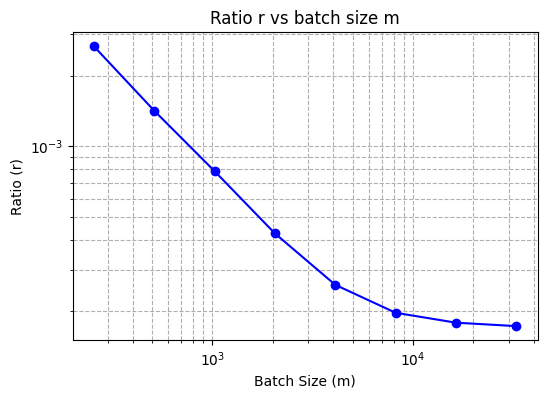

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/ishitak/.netrc.


sigma = 0.00413186970618267


Training...


wandb: Currently logged in as: ishita49 (IITB-CMInDS) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


  0%|          | 0/163 [00:00<?, ?it/s]/home/ishitak/envs/mem/lib/python3.12/site-packages/torch/autograd/graph.py:825: UserWarning: There is a performance drop because we have not yet implemented the batching rule for aten::_scaled_dot_product_flash_attention_backward. Please file us an issue on GitHub so that we can prioritize its implementation. (Triggered internally at /opt/conda/conda-bld/libtorch_1745854776362/work/aten/src/ATen/functorch/BatchedFallback.cpp:81.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
100%|██████████| 163/163 [25:55<00:00,  9.55s/it]


Epoch,▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇████
Training Loss,▇▄▆▇▆▆▆▇▇▆▆▅█▄█▇▆▇▆▁▄█▄▆▅▆▃▇▇▆▅▆▆▅▆▄▇▅▇▄
Validation accuracy,▁▅▆▇█
Epoch,1
Training Loss,1.60938
Validation accuracy,56.67072




Calculating Exposure...
6.310432456049532





... (27 outputs left out)



Calculating Exposure...
10.117787378107137





Loading weights: 100%|██████████| 338/338 [00:00<00:00, 7894.79it/s]


Exposure,▁
Number of insertions of Canary,▁
Exposure,10.11779
Number of insertions of Canary,64


Exposure,▁▄█
Number of insertions of Canary,▁▅█
Exposure,10.11779
Number of insertions of Canary,6


In [19]:
num_epochs=1
lr=1e-4
batch_size = 16
batch_size_eval=2
sub_batch_size=2
nu=[16,32,64]
sigma=-1
i=0
ratio=0.005
exp=[]
shuffle=True
can='Dear Ram, \nThe last four digits of my credit card number are 9824'
for number in nu:
    print(f'--------------------No. of insertions = {number}--------------------')

    print('Loading the dataset...')
    dataset = prep_dataset(dataset = get_dataset(ratio=0.004))
    print(dataset)

    print('\n\nTokenizing the dataset...')
    tokenized_datasets = dataset.map(
        tokenize_function, batched=True, remove_columns=["text"]
    )

    print('\n\nGrouping the dataset...')
    tokenized_datasets = tokenized_datasets.map(group_texts, batched=True, fn_kwargs={"canary":can,"num":number,"shuffle":shuffle})
    print(f"Preprocessed data: {tokenized_datasets}")# After grouping, no. of rows in tokenised_datasets might change

    print('\n\nCreating Dataloaders...')
    train_dataloader,eval_dataloader = get_dataloaders(tokenized_datasets=tokenized_datasets,per_device_train_batch_size=batch_size,per_device_eval_batch_size=batch_size_eval,sub_batch_size=sub_batch_size)

    num,max_train_steps = get_steps(train_dataloader=train_dataloader,max_train_steps=None,num_train_epochs=num_epochs)

    if sigma==-1:
        print('\n\nCalculating sigma:')
        sigma = get_sigma(T=max_train_steps,n=num*sub_batch_size/ratio, batch_size=batch_size,ep=2)
        print(f'sigma = {sigma}')

    print('\n\nTraining...')
    wandb.init(project="run-03_Exp_vary_n,e=2", name=f'Num={number}',entity="ishita49-indian-institute-of-technology-madras")
    train_model(train_dataloader=train_dataloader, eval_dataloader=eval_dataloader, learning_rate=lr,num_epoch=num_epochs,T=max_train_steps,sigma=sigma,batch_size=batch_size,n=num, sub_batch_size=sub_batch_size)
    wandb.finish()

    print('\n\nCalculating Exposure...')
    exposure=get_exposure(canary=can,n_dash=4)
    print(exposure)
    print('\n\n')
    exp.append(exposure)
    wandb.init(project="run-03_Exp_vary_n,e=2", name=f'Exposure, num={number}',entity="ishita49-indian-institute-of-technology-madras")
    wandb.log({'Exposure': exposure, 'Number of insertions of Canary': number})

    gc.collect()
    torch.cuda.empty_cache()
    device = torch.device("cuda:1")

    model = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-1.5B",
    cache_dir="/home/ishitak/ssh/run-03/FIL/qwen25_15b",
    )

    tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-1.5B",
    cache_dir="/home/ishitak/ssh/run-03/FIL/qwen25_15b",
    )

    
    tokenizer.pad_token = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.eos_token_id
    model.to(device)


wandb.init(project="run-03_Exp_vary_n,e=2", name=f'Exposure, Epsilon={exp}',entity="ishita49-indian-institute-of-technology-madras")
for i, (e, n) in enumerate(zip(exp, nu)):
    wandb.log({'Exposure': e, 'Number of insertions of Canary': math.log2(n) if n > 0 else None}, step=i)
wandb.finish()

In [21]:
import wandb

exp = [1.11685,2.0145,1.18377,3.09542,6.31043,8.00231,10.11779]
nu = [1,2,4,8,16,32,64]

wandb.init(
    project="run-03_Exp_vary_n,e=2",
    name="Exposure vs Number of insertions of Canary",
    entity="ishita49-indian-institute-of-technology-madras"
)

for x, y in zip(nu, exp):
    wandb.log({
        "Number of insertions of Canary": x,
        "Exposure": y
    })

wandb.finish()

Exposure,▁▂▁▃▅▆█
Number of insertions of Canary,▁▁▁▂▃▄█
Exposure,10.11779
Number of insertions of Canary,64
